# Lab 3 - Digits MNIST

---

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

from sklearn.neighbors import KNeighborsClassifier

## PART I - LOAD MNIST

X shape: (70000, 784)
y shape: (70000,)


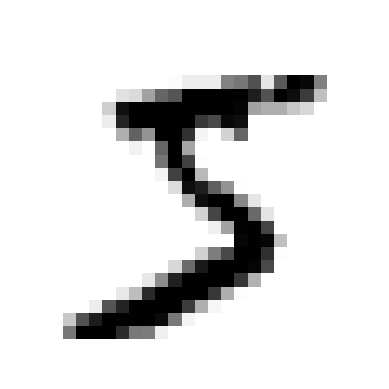

Label: 5


In [16]:
mnist = fetch_openml(
    "mnist_784",
    as_frame=False
)

X, y = mnist["data"], mnist["target"]

y = y.astype(np.uint8)

print("X shape:", X.shape)
print("y shape:", y.shape)


# Display an image
some_digit = X[0]

plt.imshow(
    some_digit.reshape(28, 28),
    cmap="binary"
)

plt.axis("off")
plt.show()

print("Label:", y[0])

## PART II - TRAIN / TEST SPLIT

In [17]:
X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]


# Binary classification: 5 vs not 5
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

## PART III - BINARY CLASSIFIER

In [18]:
sgd_clf = SGDClassifier(
    random_state=42
)

sgd_clf.fit(
    X_train,
    y_train_5
)

print(
    "Prediction:",
    sgd_clf.predict([some_digit])
)

Prediction: [ True]


## PART IV - ACCURACY

In [19]:
accuracy_scores = cross_val_score(
    sgd_clf,
    X_train,
    y_train_5,
    cv=3,
    scoring="accuracy"
)

print("Accuracy scores:", accuracy_scores)
print("Mean accuracy:", accuracy_scores.mean())

Accuracy scores: [0.95035 0.96035 0.9604 ]
Mean accuracy: 0.9570333333333334


## PART V - CONFUSION MATRIX

In [20]:
y_train_pred = cross_val_predict(
    sgd_clf,
    X_train,
    y_train_5,
    cv=3
)

cm = confusion_matrix(
    y_train_5,
    y_train_pred
)

print("Confusion matrix:")
print(cm)

Confusion matrix:
[[53892   687]
 [ 1891  3530]]


## PART VI - PRECISION / RECALL / F1

In [21]:
precision = precision_score(
    y_train_5,
    y_train_pred
)

recall = recall_score(
    y_train_5,
    y_train_pred
)

f1 = f1_score(
    y_train_5,
    y_train_pred
)

print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Precision: 0.8370879772350012
Recall: 0.6511713705958311
F1: 0.7325171197343847


## PART VII - THRESHOLD

In [22]:
y_scores = cross_val_predict(
    sgd_clf,
    X_train,
    y_train_5,
    cv=3,
    method="decision_function"
)

thresholds_to_test = [
    -5000,
    -2000,
    0,
    2000,
    5000
]

results = []

for threshold in thresholds_to_test:

    y_pred_threshold = (
        y_scores >= threshold
    )

    precision = precision_score(
        y_train_5,
        y_pred_threshold
    )

    recall = recall_score(
        y_train_5,
        y_pred_threshold
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall
    })

threshold_table = pd.DataFrame(results)

print(threshold_table)

   Threshold  Precision    Recall
0      -5000   0.624478  0.854639
1      -2000   0.777326  0.741192
2          0   0.837088  0.651171
3       2000   0.877685  0.542704
4       5000   0.916005  0.404353


## PART VIII - PRECISION / RECALL CURVE

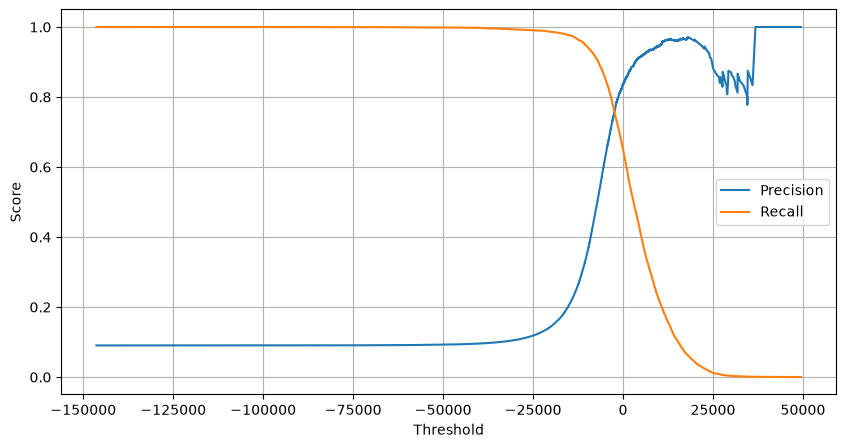

In [23]:
precisions, recalls, thresholds = precision_recall_curve(
    y_train_5,
    y_scores
)

plt.figure(figsize=(10, 5))

plt.plot(
    thresholds,
    precisions[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recalls[:-1],
    label="Recall"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.grid()
plt.legend()
plt.show()

## PART IX - ROC CURVE

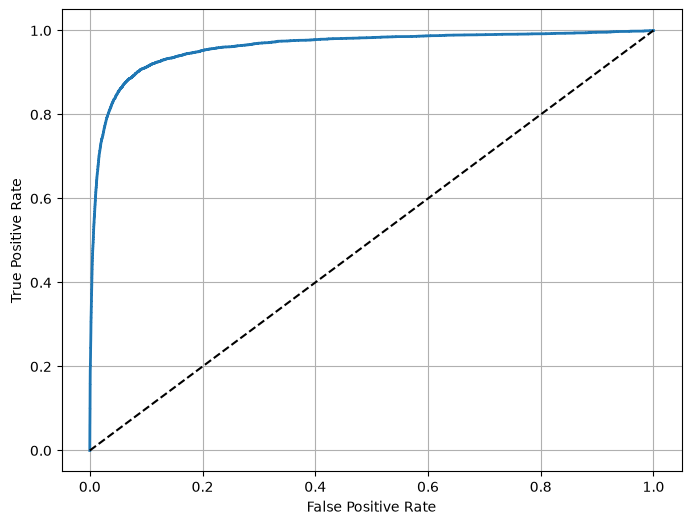

ROC-AUC: 0.9604938554008616


In [24]:
fpr, tpr, thresholds = roc_curve(
    y_train_5,
    y_scores
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid()
plt.show()


roc_auc = roc_auc_score(
    y_train_5,
    y_scores
)

print("ROC-AUC:", roc_auc)

## PART X - MULTICLASS

In [ ]:
sgd_clf.fit(
    X_train,
    y_train
)

prediction = sgd_clf.predict(
    [some_digit]
)

print("Multiclass prediction:", prediction)

In [25]:
some_digit_scores = sgd_clf.decision_function(
    [some_digit]
)

print("Decision scores:")
print(some_digit_scores)

print("Classes:")
print(sgd_clf.classes_)

Decision scores:
[2164.22030239]
Classes:
[False  True]


## PART XI - MULTICLASS CONFUSION MATRIX

In [ ]:
y_train_pred = cross_val_predict(
    sgd_clf,
    X_train,
    y_train,
    cv=3
)

conf_mx = confusion_matrix(
    y_train,
    y_train_pred
)

print("Multiclass confusion matrix:")
print(conf_mx)

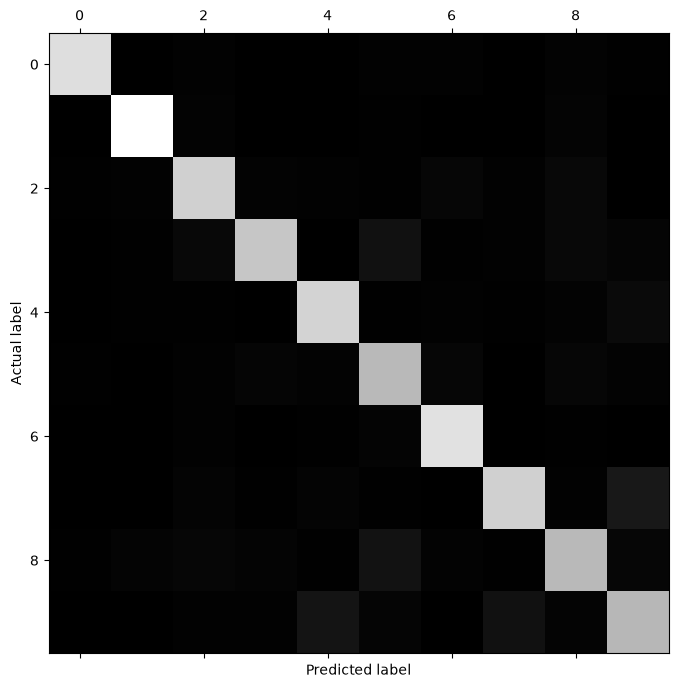

In [ ]:
plt.figure(figsize=(8, 8))

plt.matshow(
    conf_mx,
    cmap=plt.cm.gray,
    fignum=1
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")

plt.show()

## PART XII - MULTILABEL

In [27]:
y_train_large = (
    y_train >= 7
)

y_train_odd = (
    y_train % 2 == 1
)

y_multilabel = np.c_[
    y_train_large,
    y_train_odd
]


knn_clf = KNeighborsClassifier()

knn_clf.fit(
    X_train,
    y_multilabel
)

print(
    "Multilabel prediction:",
    knn_clf.predict([some_digit])
)

Multilabel prediction: [[False  True]]


## PART XIII - MULTILABEL EVALUATION

In [28]:
y_train_knn_pred = cross_val_predict(
    knn_clf,
    X_train,
    y_multilabel,
    cv=3
)

f1 = f1_score(
    y_multilabel,
    y_train_knn_pred,
    average="macro"
)

print(
    "Multilabel Macro F1:",
    f1
)

Multilabel Macro F1: 0.9764102655606048
